<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X6a_quaternions_algebra.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio VI (a): a álgebra dos quaternions

## A rotação no espaço num número de quatro partes: agora é a própria rotação que não comuta

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb)) · **Domínio:** [nó 6](X6_quaternions.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X6_quaternions.ipynb)) · **Próximo:** [X6b_quaternions_sistemas.ipynb](X6b_quaternions_sistemas.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X6b_quaternions_sistemas.ipynb))

**Objetivo.** No plano, uma rotação é um ângulo, e dois giros comutam: girar 30° e depois 40° é o mesmo que 40° e depois 30° (domínio IV). No domínio V, quem não comutava era a pose: girar e andar. No espaço, a **própria rotação** deixa de comutar: girar um livro 90° em torno de um eixo e depois 90° em torno de outro não o deixa na mesma posição que na ordem inversa. O grupo das rotações do espaço, $SO(3)$, é o primeiro grupo da série em que a parte "angular" sozinha já é não comutativa.

Os **quaternions** de Hamilton (1843), $q=w+x\,\mathbf i+y\,\mathbf j+z\,\mathbf k$ com

$$\mathbf i^2=\mathbf j^2=\mathbf k^2=\mathbf{ijk}=-1,$$

fazem pela rotação do espaço o que os complexos unitários fizeram pela rotação do plano: um giro de ângulo $\theta$ em torno do eixo unitário $\mathbf n$ é $q=\cos\frac\theta2+\mathrm{sen}\frac\theta2\,(n_x\mathbf i+n_y\mathbf j+n_z\mathbf k)$, compor giros é multiplicar, e desfazer é conjugar. O meio ângulo, que no domínio V já aparecia ($r=e^{i\theta/2}$), agora é essencial, e tem uma consequência física estranha: uma volta de 360° **não** traz o quaternion de volta ao início.

**Roteiro**
1. A álgebra: o produto de Hamilton, a norma que se multiplica, as matrizes $2\times2$ complexas
2. Girar vetores: $q\,v\,q^*$, a matriz de rotação e o teste do livro
3. A dupla cobertura: 360° não é uma volta, 720° é
4. Ângulos de Euler e o bloqueio do cardã (*gimbal lock*), da Apollo 11 aos drones
5. Exp e Log: o vetor de rotação e duas fórmulas que perdem dígitos
6. Interpolar orientações: SLERP, a reta normalizada e os ângulos de Euler
7. Sortear rotações uniformemente: o viés dos ângulos de Euler
8. Rotações exatas com quaternions inteiros
9. A interface de domínio para $SO(3)$
10. Exercícios

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido), np.asarray(esperado)
    tipo = complex if (np.iscomplexobj(a) or np.iscomplexobj(b)) else float      # aceita complexos (domínio IV)
    a, b = a.astype(tipo), b.astype(tipo)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

import sympy as sp
from fractions import Fraction
from scipy import stats
rng = np.random.default_rng(61)

class Q:
    """Quaternion w + x i + y j + z k. As componentes podem ser floats, Fractions, inteiros ou números duais."""
    def __init__(self, w, x=0, y=0, z=0): self.w, self.x, self.y, self.z = w, x, y, z
    def __mul__(self, o):
        if not isinstance(o, Q):                           # quaternion vezes escalar
            return Q(self.w * o, self.x * o, self.y * o, self.z * o)
        a, b = self, o
        return Q(a.w * b.w - a.x * b.x - a.y * b.y - a.z * b.z,
                 a.w * b.x + a.x * b.w + a.y * b.z - a.z * b.y,
                 a.w * b.y - a.x * b.z + a.y * b.w + a.z * b.x,
                 a.w * b.z + a.x * b.y - a.y * b.x + a.z * b.w)
    def __rmul__(self, s): return Q(s * self.w, s * self.x, s * self.y, s * self.z)
    def __add__(self, o): return Q(self.w + o.w, self.x + o.x, self.y + o.y, self.z + o.z)
    def __sub__(self, o): return Q(self.w - o.w, self.x - o.x, self.y - o.y, self.z - o.z)
    def __neg__(self): return Q(-self.w, -self.x, -self.y, -self.z)
    def conj(self): return Q(self.w, -self.x, -self.y, -self.z)
    def norma2(self): return self.w * self.w + self.x * self.x + self.y * self.y + self.z * self.z
    def vet(self): return np.array([self.w, self.x, self.y, self.z])
    def __eq__(self, o): return all(p == r for p, r in zip(self.vet(), o.vet()))
    def __repr__(self): return f"({self.w}) + ({self.x})i + ({self.y})j + ({self.z})k"

def sinc(x):
    """sen(x)/x, sem perder dígitos perto de 0 (np.sinc usa sen(πx)/(πx))."""
    return np.sinc(np.asarray(x, float) / np.pi)

def qmul(a, b):
    """Produto de Hamilton de quaternions guardados como arrays (w, x, y, z); aceita pilhas (..., 4)."""
    a, b = np.asarray(a), np.asarray(b)
    w1, x1, y1, z1 = np.moveaxis(a, -1, 0); w2, x2, y2, z2 = np.moveaxis(b, -1, 0)
    return np.stack([w1 * w2 - x1 * x2 - y1 * y2 - z1 * z2,
                     w1 * x2 + x1 * w2 + y1 * z2 - z1 * y2,
                     w1 * y2 - x1 * z2 + y1 * w2 + z1 * x2,
                     w1 * z2 + x1 * y2 - y1 * x2 + z1 * w2], axis=-1)

def qconj(q):
    q = np.asarray(q); return q * np.array([1, -1, -1, -1])

def qnorm(q):
    q = np.asarray(q, float); return q / np.linalg.norm(q, axis=-1, keepdims=True)

def qrot(q, v):
    """O vetor v (3,) levado pela rotação q: a parte vetorial de q (0, v) q*."""
    return qmul(qmul(q, np.concatenate([[0.0], v])), qconj(q))[1:]

def qmat(q):
    """A matriz de rotação R(q), com R v = q v q* (q unitário)."""
    w, x, y, z = q
    return np.array([[1 - 2 * (y * y + z * z), 2 * (x * y - w * z), 2 * (x * z + w * y)],
                     [2 * (x * y + w * z), 1 - 2 * (x * x + z * z), 2 * (y * z - w * x)],
                     [2 * (x * z - w * y), 2 * (y * z + w * x), 1 - 2 * (x * x + y * y)]])

def mat_q(R):
    """De uma matriz de rotação para um quaternion (método de Shepperd: usa o maior pivô, sem perder dígitos)."""
    t = np.trace(R); d = np.diag(R)
    k = np.argmax([t, *d])
    if k == 0:
        w = np.sqrt(1 + t) / 2; q = [w, (R[2, 1] - R[1, 2]) / (4 * w), (R[0, 2] - R[2, 0]) / (4 * w), (R[1, 0] - R[0, 1]) / (4 * w)]
    elif k == 1:
        x = np.sqrt(1 + 2 * d[0] - t) / 2; q = [(R[2, 1] - R[1, 2]) / (4 * x), x, (R[0, 1] + R[1, 0]) / (4 * x), (R[0, 2] + R[2, 0]) / (4 * x)]
    elif k == 2:
        y = np.sqrt(1 + 2 * d[1] - t) / 2; q = [(R[0, 2] - R[2, 0]) / (4 * y), (R[0, 1] + R[1, 0]) / (4 * y), y, (R[1, 2] + R[2, 1]) / (4 * y)]
    else:
        z = np.sqrt(1 + 2 * d[2] - t) / 2; q = [(R[1, 0] - R[0, 1]) / (4 * z), (R[0, 2] + R[2, 0]) / (4 * z), (R[1, 2] + R[2, 1]) / (4 * z), z]
    q = np.array(q); return q if q[0] >= 0 else -q

def qexp(phi):
    """Exp do vetor de rotação φ = θ n: (cos(θ/2), sen(θ/2) n), com o sinc estável perto de θ = 0."""
    phi = np.asarray(phi, float); th = np.linalg.norm(phi)
    return np.concatenate([[np.cos(th / 2)], 0.5 * sinc(th / 2) * phi])

def qlog(q):
    """Log: o vetor de rotação φ de q (escolhendo o representante com w ≥ 0, isto é, |θ| ≤ π)."""
    q = np.asarray(q, float)
    if q[0] < 0: q = -q
    s = np.linalg.norm(q[1:]); th = 2 * np.arctan2(s, q[0])     # atan2: estável para ângulos pequenos e grandes
    return 2 * q[1:] / sinc(th / 2)

def slerp(q0, q1, s):
    """Interpolação esférica: q0 Exp(s Log(q0* q1)), pelo arco mais curto."""
    return qmul(q0, qexp(s * qlog(qmul(qconj(q0), q1))))

def chapeu(v):
    """A matriz antissimétrica [v]×, com [v]× u = v × u."""
    return np.array([[0, -v[2], v[1]], [v[2], 0, -v[0]], [-v[1], v[0], 0]])

---

## 1. A álgebra

O produto de dois quaternions sai da distributividade e das regras $\mathbf i^2=\mathbf j^2=\mathbf k^2=\mathbf{ijk}=-1$, que implicam $\mathbf{ij}=\mathbf k=-\mathbf{ji}$, $\mathbf{jk}=\mathbf i=-\mathbf{kj}$, $\mathbf{ki}=\mathbf j=-\mathbf{ik}$. Escrevendo $q=(w,\mathbf v)$, com $w$ a parte escalar e $\mathbf v$ a parte vetorial, o produto tem uma forma que junta o produto escalar e o vetorial:

$$(w_1,\mathbf v_1)(w_2,\mathbf v_2)=\big(w_1w_2-\mathbf v_1\cdot\mathbf v_2,\ \ w_1\mathbf v_2+w_2\mathbf v_1+\mathbf v_1\times\mathbf v_2\big).$$

O produto vetorial é o responsável pela não comutatividade: ele troca de sinal quando os fatores trocam de lugar. O conjugado é $q^*=(w,-\mathbf v)$, e $qq^*=w^2+|\mathbf v|^2=|q|^2$, um número real. A norma **se multiplica**, $|pq|=|p|\,|q|$, o que é a **identidade dos quatro quadrados de Euler** (1748): o produto de duas somas de quatro quadrados é uma soma de quatro quadrados. Os quaternions unitários formam, portanto, um grupo: a esfera $S^3$ de $\mathbb R^4$.

In [2]:
um, i, j, k = Q(1), Q(0, 1), Q(0, 0, 1), Q(0, 0, 0, 1)
confere("i² = j² = k² = ijk = −1", [(i * i).vet(), (j * j).vet(), (k * k).vet(), (i * j * k).vet()], [(-um).vet()] * 4)
confere("ij = k e ji = −k", [(i * j).vet(), (j * i).vet()], [k.vet(), (-k).vet()])
confere("jk = i, ki = j", [(j * k).vet(), (k * i).vet()], [i.vet(), j.vet()])

# a forma (escalar, vetor), com produto escalar e vetorial
p, q = rng.normal(size=4), rng.normal(size=4)
w = p[0] * q[0] - p[1:] @ q[1:]
v = p[0] * q[1:] + q[0] * p[1:] + np.cross(p[1:], q[1:])
confere("produto = (w1w2 − v1·v2, w1v2 + w2v1 + v1×v2)", qmul(p, q), np.concatenate([[w], v]), tol=1e-14)
print("pq − qp =", qmul(p, q) - qmul(q, p), " = (0, 2 v1×v2):", 2 * np.cross(p[1:], q[1:]))

# simbólico: associatividade e os quatro quadrados de Euler
s = sp.symbols("a0:4 b0:4 c0:4", real=True)
A, B, C = Q(*s[0:4]), Q(*s[4:8]), Q(*s[8:12])
confere("associatividade, simbolicamente", [sp.expand(e) for e in ((A * B) * C - A * (B * C)).vet()], [0] * 4)
confere("|AB|² = |A|²|B|² (identidade dos quatro quadrados)", sp.expand((A * B).norma2() - A.norma2() * B.norma2()), 0)

OK   i² = j² = k² = ijk = −1:  diferença máxima = 0.00e+00
OK   ij = k e ji = −k:  diferença máxima = 0.00e+00
OK   jk = i, ki = j:  diferença máxima = 0.00e+00
OK   produto = (w1w2 − v1·v2, w1v2 + w2v1 + v1×v2):  diferença máxima = 8.88e-16
pq − qp = [ 0.       -0.115924 -3.484963 -3.16892 ]  = (0, 2 v1×v2): [-0.115924 -3.484963 -3.16892 ]
OK   associatividade, simbolicamente:  diferença máxima = 0.00e+00
OK   |AB|² = |A|²|B|² (identidade dos quatro quadrados):  diferença máxima = 0.00e+00


**Quaternions como matrizes $2\times2$ complexas.** Assim como o complexo $a+bi$ é a matriz $\begin{bmatrix}a&-b\\b&a\end{bmatrix}$ (domínio IV), o quaternion $q=w+x\mathbf i+y\mathbf j+z\mathbf k$, com $\alpha=w+xi$ e $\beta=y+zi$, é a matriz

$$M(q)=\begin{bmatrix}\alpha&\beta\\-\bar\beta&\bar\alpha\end{bmatrix},\qquad M(pq)=M(p)\,M(q),\qquad \det M(q)=|q|^2.$$

Os quaternions unitários são exatamente as matrizes unitárias de determinante 1, o grupo $SU(2)$. É o mesmo grupo que descreve o spin do elétron e as portas de um qubit (o apêndice de computação quântica deste domínio explora isso). E o produto de matrizes é associativo e não comutativo, o que explica de graça as duas propriedades acima.

In [3]:
def M(q):
    al, be = q.w + sp.I * q.x, q.y + sp.I * q.z
    return sp.Matrix([[al, be], [-sp.conjugate(be), sp.conjugate(al)]])

confere("M(AB) = M(A) M(B), simbolicamente", list(sp.expand(M(A * B) - M(A) * M(B))), [0] * 4)
confere("det M(A) = |A|²", sp.expand(M(A).det() - A.norma2()), 0)
print("M(i) =", M(i).tolist(), "  M(j) =", M(j).tolist(), "  M(k) =", M(k).tolist())

OK   M(AB) = M(A) M(B), simbolicamente:  diferença máxima = 0.00e+00
OK   det M(A) = |A|²:  diferença máxima = 0.00e+00
M(i) = [[I, 0], [0, -I]]   M(j) = [[0, 1], [-1, 0]]   M(k) = [[0, I], [I, 0]]


---

## 2. Girar vetores

Um vetor $\mathbf v$ vira o quaternion puro $(0,\mathbf v)$, e a rotação $q$ o leva em $q\,(0,\mathbf v)\,q^*$. Duas conferências justificam a fórmula: o resultado é de novo um quaternion puro, com o mesmo comprimento, e ele coincide com a **fórmula de Rodrigues** para o giro de $\theta$ em torno de $\mathbf n$:

$$R\,\mathbf v=\mathbf v\cos\theta+(\mathbf n\times\mathbf v)\,\mathrm{sen}\,\theta+\mathbf n\,(\mathbf n\cdot\mathbf v)(1-\cos\theta).$$

A rotação depende de $q$ quadraticamente, e por isso **$q$ e $-q$ dão a mesma rotação**: cada rotação tem dois quaternions, como cada pose do plano tinha dois dual-complexos.

**A convenção deste domínio.** $R(q)$ leva coordenadas do **corpo** para o **mundo**: $\mathbf v_{\text{mundo}}=q\,\mathbf v_{\text{corpo}}\,q^*$. Compor é multiplicar, e a ordem segue a das matrizes: $q_1q_2$ é "girar por $q_2$ e depois por $q_1$", ambos medidos no mundo; ou, lendo da esquerda para a direita, "girar por $q_1$ e depois por $q_2$ **medido no novo referencial do corpo**". As duas leituras descrevem o mesmo produto.

In [4]:
def eixo_angulo(n, th):
    n = np.asarray(n, float); n = n / np.linalg.norm(n)
    return np.concatenate([[np.cos(th / 2)], np.sin(th / 2) * n])

def rodrigues(n, th, v):
    n = np.asarray(n, float) / np.linalg.norm(n)
    return v * np.cos(th) + np.cross(n, v) * np.sin(th) + n * (n @ v) * (1 - np.cos(th))

n, th, v = rng.normal(size=3), 1.234, rng.normal(size=3)
q = eixo_angulo(n, th)
qvq = qmul(qmul(q, np.concatenate([[0], v])), qconj(q))
confere("q v q* é um quaternion puro", qvq[0], 0, tol=1e-15)
confere("e tem o comprimento de v", np.linalg.norm(qvq[1:]), np.linalg.norm(v), tol=1e-15)
confere("q v q* = fórmula de Rodrigues", qvq[1:], rodrigues(n, th, v), tol=1e-14)
R = qmat(q)
confere("R(q) é ortogonal", R.T @ R, np.eye(3), tol=1e-14)
confere("com determinante 1", np.linalg.det(R), 1.0, tol=1e-14)
confere("q e −q dão a mesma rotação", qmat(-q), R, tol=1e-15)
a, b = qnorm(rng.normal(size=4)), qnorm(rng.normal(size=4))
confere("R(ab) = R(a) R(b): compor é multiplicar", qmat(qmul(a, b)), qmat(a) @ qmat(b), tol=1e-14)

OK   q v q* é um quaternion puro:  diferença máxima = 5.55e-17
OK   e tem o comprimento de v:  diferença máxima = 2.22e-16
OK   q v q* = fórmula de Rodrigues:  diferença máxima = 2.22e-16
OK   R(q) é ortogonal:  diferença máxima = 2.22e-16
OK   com determinante 1:  diferença máxima = 2.22e-16
OK   q e −q dão a mesma rotação:  diferença máxima = 0.00e+00
OK   R(ab) = R(a) R(b): compor é multiplicar:  diferença máxima = 3.89e-16


**O teste do livro.** Um livro sobre a mesa, com a lombada apontando para $+x$ e a capa para cima ($+z$). Duas sequências, com os eixos fixos no mundo: (A) 90° em torno de $x$ e depois 90° em torno de $y$; (B) a ordem inversa. Para onde aponta a capa em cada caso? E qual é a rotação única equivalente a cada sequência?

A: x depois y:  lombada → [ 0.  0. -1.],  capa → [ 0. -1.  0.];  equivale a 120.0° em torno de [ 1.  1. -1.]/√3
B: y depois x:  lombada → [ 0.  1. -0.],  capa → [ 1. -0.  0.];  equivale a 120.0° em torno de [1. 1. 1.]/√3
OK   as duas ordens dão orientações diferentes:  diferença máxima = 0.00e+00
OK   e cada uma equivale a um único giro de 120°:  diferença máxima = 0.00e+00


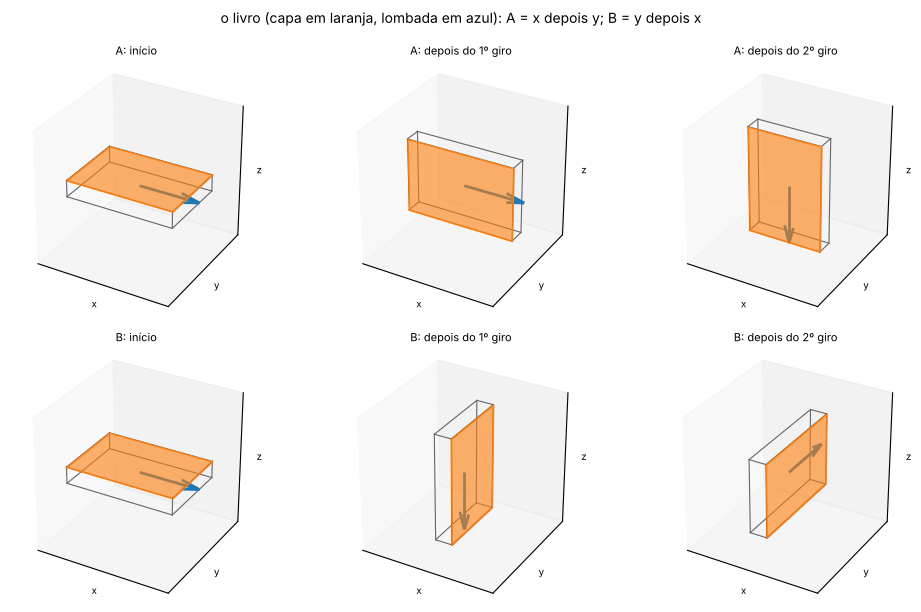

In [5]:
qx, qy = eixo_angulo([1, 0, 0], np.pi / 2), eixo_angulo([0, 1, 0], np.pi / 2)
qA = qmul(qy, qx)                       # primeiro x, depois y (eixos do mundo): o segundo multiplica pela esquerda
qB = qmul(qx, qy)
for nome, qq in [("A: x depois y", qA), ("B: y depois x", qB)]:
    phi = qlog(qq); ang = np.linalg.norm(phi)
    print(f"{nome}:  lombada → {np.round(qrot(qq, [1, 0, 0]), 12)},  capa → {np.round(qrot(qq, [0, 0, 1]), 12)};  "
          f"equivale a {np.degrees(ang):.1f}° em torno de {np.round(phi / ang * np.sqrt(3), 6)}/√3")
confere("as duas ordens dão orientações diferentes", np.linalg.norm(qmat(qA) - qmat(qB)) > 1, True)
confere("e cada uma equivale a um único giro de 120°", [np.linalg.norm(qlog(qA)), np.linalg.norm(qlog(qB))], [2 * np.pi / 3] * 2, tol=1e-14)

def desenha_livro(ax, qq, titulo):
    L = np.array([1.6, 1.1, 0.25]) / 2                  # meia lombada (x), meia largura (y), meia espessura (z)
    cantos = np.array([[sx, sy, sz] for sx in (-1, 1) for sy in (-1, 1) for sz in (-1, 1)]) * L
    P = cantos @ qmat(qq).T
    for a_ in range(8):
        for b_ in range(a_ + 1, 8):
            if np.sum(np.abs(cantos[a_] - cantos[b_]) > 1e-9) == 1:
                ax.plot(*P[[a_, b_]].T, color="0.4", lw=0.8)
    capa = P[cantos[:, 2] > 0][[0, 1, 3, 2]]
    ax.add_collection3d(__import__("mpl_toolkits.mplot3d.art3d", fromlist=["Poly3DCollection"]).Poly3DCollection([capa], color="C1", alpha=0.6))
    lomb = qrot(qq, [0.9, 0, 0]); ax.quiver(0, 0, 0, *lomb, color="C0", lw=2)
    ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_zlim(-1, 1); ax.set_box_aspect((1, 1, 1))
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([]); ax.set_title(titulo, fontsize=8)
    ax.set_xlabel("x", fontsize=7, labelpad=-12); ax.set_ylabel("y", fontsize=7, labelpad=-12); ax.set_zlabel("z", fontsize=7, labelpad=-12)

fig = plt.figure(figsize=(10, 6.2))
for lin, (q1, q2, nome) in enumerate([(qx, qy, "A"), (qy, qx, "B")]):
    for col, (qq, tit) in enumerate([(np.array([1.0, 0, 0, 0]), "início"), (q1, "depois do 1º giro"), (qmul(q2, q1), "depois do 2º giro")]):
        desenha_livro(fig.add_subplot(2, 3, 3 * lin + col + 1, projection="3d"), qq, f"{nome}: {tit}")
fig.suptitle("o livro (capa em laranja, lombada em azul): A = x depois y; B = y depois x", fontsize=10)
plt.tight_layout(); plt.show()

---

## 3. A dupla cobertura: 360° não é uma volta

O giro de $\theta$ em torno de $\mathbf z$ é $q(\theta)=\cos\frac\theta2+\mathbf k\,\mathrm{sen}\frac\theta2$. Em $\theta=360°$, a rotação volta à identidade, mas o quaternion vale $-1$; só em $720°$ ele volta a $+1$. Cada rotação tem dois quaternions, e um caminho contínuo de rotações se **levanta** a um caminho contínuo de quaternions, escolhendo a cada passo o sinal mais próximo do anterior.

Isso classifica os laços fechados de rotações em dois tipos: os que se levantam a um laço fechado (terminam em $+q_0$) e os que terminam em $-q_0$. Um laço do segundo tipo **não pode ser deformado continuamente até o laço parado**, por mais que se tente: é o **truque do cinto** (ou do prato de Dirac). Segure a fivela de um cinto, gire-a 360° e o cinto fica torcido, sem como desfazer a torção só transladando a fivela; gire mais 360° no mesmo sentido, e a torção dupla se desfaz passando o cinto em volta da fivela. A célula levanta quatro laços a partir das **matrizes** de rotação (que não sabem nada de sinal) e lê o sinal no fim.

OK   o laço '360° em torno de z' é fechado nas matrizes:  diferença máxima = 2.45e-16
    levantado, termina em -1 vez o quaternion inicial
OK   o laço '720° em torno de z' é fechado nas matrizes:  diferença máxima = 4.90e-16
    levantado, termina em +1 vez o quaternion inicial
OK   o laço '360° em z, depois 360° em x' é fechado nas matrizes:  diferença máxima = 2.45e-16
    levantado, termina em +1 vez o quaternion inicial
OK   o laço 'uma oscilação qualquer (vai e volta)' é fechado nas matrizes:  diferença máxima = 3.92e-16
    levantado, termina em +1 vez o quaternion inicial
OK   360° termina em −1; 720° e 360°+360° terminam em +1; a oscilação, em +1:  diferença máxima = 0.00e+00


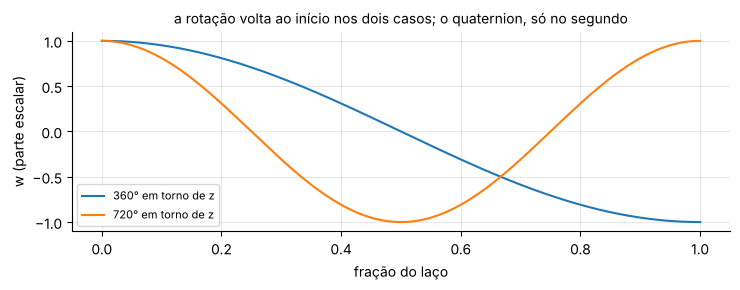

In [6]:
def levanta(Rs):
    """Levanta um caminho de matrizes de rotação a um caminho contínuo de quaternions."""
    qs = [mat_q(Rs[0])]
    for R_ in Rs[1:]:
        q_ = mat_q(R_)
        qs.append(q_ if q_ @ qs[-1] >= 0 else -q_)
    return np.array(qs)

t = np.linspace(0, 1, 721)
laços = {
    "360° em torno de z": [qmat(eixo_angulo([0, 0, 1], 2 * np.pi * s)) for s in t],
    "720° em torno de z": [qmat(eixo_angulo([0, 0, 1], 4 * np.pi * s)) for s in t],
    "360° em z, depois 360° em x": [qmat(eixo_angulo([0, 0, 1], 4 * np.pi * s)) if s < 0.5 else qmat(eixo_angulo([1, 0, 0], 4 * np.pi * (s - 0.5))) for s in t],
    "uma oscilação qualquer (vai e volta)": [qmat(qexp(0.8 * np.sin(2 * np.pi * s) * np.array([1, 2, 0.5]))) for s in t],
}
sinais = {}
for nome, Rs in laços.items():
    confere(f"o laço '{nome}' é fechado nas matrizes", Rs[-1], Rs[0], tol=1e-12)
    qs = levanta(Rs); sinais[nome] = qs[-1] @ qs[0]
    print(f"    levantado, termina em {sinais[nome]:+.0f} vez o quaternion inicial")
confere("360° termina em −1; 720° e 360°+360° terminam em +1; a oscilação, em +1", list(sinais.values()), [-1, 1, 1, 1], tol=1e-12)

fig, ax = plt.subplots(figsize=(7.5, 3))
for nome in ["360° em torno de z", "720° em torno de z"]:
    ax.plot(t, levanta(laços[nome])[:, 0], label=nome)
ax.set_xlabel("fração do laço"); ax.set_ylabel("w (parte escalar)"); ax.legend(fontsize=8)
ax.set_title("a rotação volta ao início nos dois casos; o quaternion, só no segundo", fontsize=10)
plt.tight_layout(); plt.show()

**Leitura.** Os quatro laços são fechados nas matrizes, e o levantamento separa dois tipos. Uma volta de 360° termina em $-1$. Duas voltas de 360°, no mesmo eixo **ou em eixos diferentes**, terminam em $+1$: é por isso que o cinto torcido duas vezes se desfaz. A oscilação de vai e volta termina em $+1$, como qualquer laço que se pode encolher até um ponto. A dupla cobertura não é um artefato da notação: ela tem efeitos físicos (o spin de um elétron muda de sinal numa volta de 360°) e efeitos de engenharia, que reaparecem no controle de atitude (o apêndice do *unwinding*) e no filtro de Kalman (a etapa (d)).

---

## 4. Ângulos de Euler e o bloqueio do cardã

A alternativa mais popular aos quaternions são os **ângulos de Euler**: três giros sucessivos em torno de eixos coordenados. Na convenção de aviões e drones (guinada $\psi$, arfagem $\theta$, rolagem $\phi$, a ordem ZYX), $R=R_z(\psi)\,R_y(\theta)\,R_x(\phi)$. São três números com significado intuitivo, mas a relação entre as **taxas** dos ângulos e a velocidade angular $\boldsymbol\omega$ medida pelo giroscópio é

$$\begin{bmatrix}\dot\phi\\\dot\theta\\\dot\psi\end{bmatrix}=\frac1{\cos\theta}\begin{bmatrix}\cos\theta&\mathrm{sen}\,\phi\,\mathrm{sen}\,\theta&\cos\phi\,\mathrm{sen}\,\theta\\0&\cos\phi\cos\theta&-\mathrm{sen}\,\phi\cos\theta\\0&\mathrm{sen}\,\phi&\cos\phi\end{bmatrix}\boldsymbol\omega,$$

e o $1/\cos\theta$ explode em $\theta=\pm90°$: com o nariz apontando para cima, guinada e rolagem giram em torno do **mesmo** eixo, e um grau de liberdade se perde. Num conjunto mecânico de três cardãs (*gimbals*), dois eixos ficam alinhados, e o conjunto trava: é o *gimbal lock*.

**A Apollo.** A plataforma inercial das naves Apollo tinha três cardãs. Segundo o Apollo Lunar Surface Journal (Jones e Fjeld), no módulo lunar o computador acendia um aviso de *gimbal lock* quando o cardã do meio passava de 70° e congelava a plataforma em 85°, exigindo um realinhamento pelas estrelas; o cálculo dos ângulos comandados dividia pelo cosseno do ângulo do meio. Os engenheiros sabiam do problema e decidiram não usar um quarto cardã. Michael Collins, depois do pouso do módulo lunar na Apollo 11, brincou pedindo que lhe mandassem "um quarto cardã de Natal". Com quaternions não há cardã nem divisão por cosseno: a rotação é integrada diretamente.

A célula gira um corpo com velocidade angular constante **no corpo**, de modo que a arfagem passa por 90°, e integra a orientação de duas maneiras: pelos ângulos de Euler (RK4) e pela fórmula exata $q(t)=q_0\,\mathrm{Exp}(\boldsymbol\omega t)$.

OK   as taxas de Euler reproduzem dR/dt = R [ω]×:  diferença máxima = 7.21e-11


OK   o quaternion exato continua unitário:  diferença máxima = 2.22e-16
a arfagem verdadeira chega a 89.52° em t = 2.62 s
erro de orientação dos ângulos de Euler (RK4, Δt = 0.01 s): antes da passagem 1.3e-12 rad, no fim 1.0e-05 rad
OK   longe da singularidade, Euler + RK4 é preciso:  diferença máxima = 0.00e+00
a velocidade angular é 0.60 rad/s, mas a maior taxa de um ângulo de Euler chega a 70 rad/s
OK   depois de passar perto de 90°, o erro cresce mais de quatro ordens de grandeza:  diferença máxima = 0.00e+00


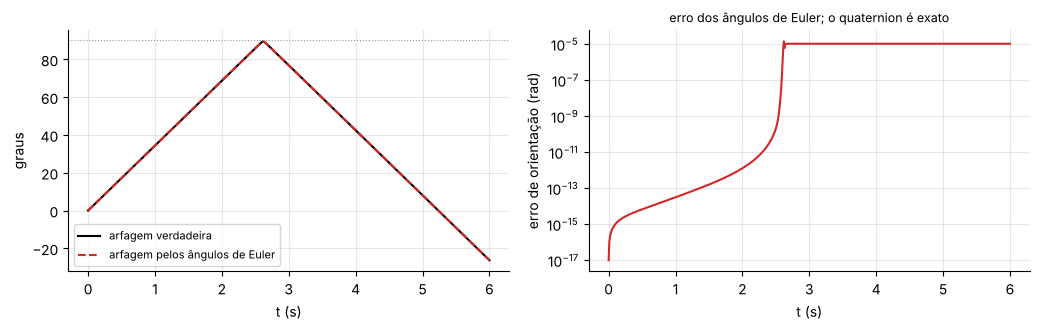

In [7]:
def euler_mat(ang):
    phi, th, psi = ang
    Rx = np.array([[1, 0, 0], [0, np.cos(phi), -np.sin(phi)], [0, np.sin(phi), np.cos(phi)]])
    Ry = np.array([[np.cos(th), 0, np.sin(th)], [0, 1, 0], [-np.sin(th), 0, np.cos(th)]])
    Rz = np.array([[np.cos(psi), -np.sin(psi), 0], [np.sin(psi), np.cos(psi), 0], [0, 0, 1]])
    return Rz @ Ry @ Rx

def taxas_euler(ang, w):
    phi, th, _ = ang
    E = np.array([[np.cos(th), np.sin(phi) * np.sin(th), np.cos(phi) * np.sin(th)],
                  [0, np.cos(phi) * np.cos(th), -np.sin(phi) * np.cos(th)],
                  [0, np.sin(phi), np.cos(phi)]]) / np.cos(th)
    return E @ w

# conferência da fórmula das taxas: derivada numérica de R, comparada com R [ω]×
ang0, w0 = np.array([0.3, 0.5, -0.4]), np.array([0.2, -0.7, 0.4])
h = 1e-6
dR = (euler_mat(ang0 + h * taxas_euler(ang0, w0)) - euler_mat(ang0 - h * taxas_euler(ang0, w0))) / (2 * h)
confere("as taxas de Euler reproduzem dR/dt = R [ω]×", dR, euler_mat(ang0) @ chapeu(w0), tol=1e-8)

w = np.array([0.003, 0.6, 0.002])                  # rad/s no corpo: sobe o nariz, passando a meio grau da vertical
dt, T = 0.01, 6.0
ang, ts, erro_euler, arf, taxa_max = np.zeros(3), [], [], [], 0.0
for n_ in range(int(T / dt) + 1):
    t_ = n_ * dt
    R_ver = qmat(qexp(w * t_))                     # a orientação exata
    R_eul = euler_mat(ang)
    erro_euler.append(np.linalg.norm(qlog(mat_q(R_eul.T @ R_ver))))
    arf.append(np.degrees(ang[1])); ts.append(t_)
    k1 = taxas_euler(ang, w); taxa_max = max(taxa_max, np.abs(k1).max()); k2 = taxas_euler(ang + dt / 2 * k1, w)
    k3 = taxas_euler(ang + dt / 2 * k2, w); k4 = taxas_euler(ang + dt * k3, w)
    ang = ang + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
erro_euler = np.array(erro_euler); arf = np.array(arf)
q_fim = qexp(w * T)
confere("o quaternion exato continua unitário", np.linalg.norm(q_fim), 1, tol=1e-15)
arf_ver = np.degrees([np.arcsin(-qmat(qexp(w * t_))[2, 0]) for t_ in ts])
print(f"a arfagem verdadeira chega a {arf_ver.max():.2f}° em t = {ts[np.argmax(arf_ver)]:.2f} s")
print(f"erro de orientação dos ângulos de Euler (RK4, Δt = {dt} s): antes da passagem {erro_euler[ts.index(2.0)]:.1e} rad, no fim {erro_euler[-1]:.1e} rad")
confere("longe da singularidade, Euler + RK4 é preciso", erro_euler[ts.index(2.0)] < 1e-8, True)
print(f"a velocidade angular é {np.linalg.norm(w):.2f} rad/s, mas a maior taxa de um ângulo de Euler chega a {taxa_max:.0f} rad/s")
confere("depois de passar perto de 90°, o erro cresce mais de quatro ordens de grandeza", erro_euler[-1] > 1e4 * erro_euler[ts.index(2.0)], True)

fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.4))
axs[0].plot(ts, arf_ver, "k-", label="arfagem verdadeira"); axs[0].plot(ts, arf, "C3--", label="arfagem pelos ângulos de Euler")
axs[0].axhline(90, color="0.6", lw=0.8, ls=":"); axs[0].set_xlabel("t (s)"); axs[0].set_ylabel("graus"); axs[0].legend(fontsize=8)
axs[1].semilogy(ts, np.maximum(erro_euler, 1e-17), "C3-"); axs[1].set_xlabel("t (s)"); axs[1].set_ylabel("erro de orientação (rad)")
axs[1].set_title("erro dos ângulos de Euler; o quaternion é exato", fontsize=9)
plt.tight_layout(); plt.show()

**Leitura.** Longe da singularidade, os ângulos de Euler com RK4 acompanham a orientação exata com erro de $10^{-12}$ rad. Quando a arfagem passa a meio grau da vertical (89,5°, em $t\approx2{,}6$ s), as taxas de guinada e rolagem chegam a 70 rad/s, para uma velocidade angular de apenas 0,6 rad/s: os dois ângulos giram depressa, em sentidos opostos, para descrever um movimento que, no corpo, é lento. O RK4 com passo fixo não acompanha essa corrida, e o erro salta sete ordens de grandeza, para $10^{-5}$ rad, e **fica**: depois da passagem, o erro não volta. A curva da arfagem, à esquerda, não mostra nada disso a olho, e é por isso que o problema engana. Uma passagem mais perto de 90° daria um erro maior; em 90° exatos, a divisão é por zero. O quaternion integra a mesma rotação como uma exponencial, sem singularidade em lugar nenhum.

---

## 5. Exp e Log: o vetor de rotação

O **vetor de rotação** $\boldsymbol\varphi=\theta\,\mathbf n$ (o eixo, com comprimento igual ao ângulo) é a coordenada natural do espaço tangente: é ele que um giroscópio integra em um passo, e é ele o erro de orientação de um filtro de Kalman. As duas pontes são

$$\mathrm{Exp}(\boldsymbol\varphi)=\Big(\cos\tfrac\theta2,\ \tfrac12\,\mathrm{sinc}\tfrac\theta2\,\boldsymbol\varphi\Big),\qquad \mathrm{Log}(q)=\frac{2\,\mathbf v}{\mathrm{sinc}(\theta/2)},\quad\theta=2\,\mathrm{atan2}(|\mathbf v|,w).$$

O $\mathrm{sinc}$ evita a divisão $0/0$ perto de $\theta=0$, como no domínio V. Mas há um segundo cuidado, no **ângulo**: as fórmulas de livro $\theta=2\arccos w$ e $\theta=2\arcsin|\mathbf v|$ perdem dígitos, a primeira perto de $0$ (onde $w\approx1$ e o $\arccos$ tem derivada infinita) e a segunda perto de $\pi$. O $\mathrm{atan2}$ usa as duas partes e não perde nada.

In [8]:
print("     θ          2 arccos(w)       2 arcsin(|v|)       2 atan2(|v|, w)      (erros relativos)")
erros = {"acos": [], "asin": [], "atan2": []}
for th in [1e-12, 1e-8, 1e-4, 1.0, np.pi - 1e-4, np.pi - 1e-8]:
    q = eixo_angulo([1, 2, 3], th)
    s_ = np.linalg.norm(q[1:])
    e = {"acos": abs(2 * np.arccos(min(q[0], 1.0)) - th) / th, "asin": abs(2 * np.arcsin(min(s_, 1.0)) - th) / th,
         "atan2": abs(2 * np.arctan2(s_, q[0]) - th) / th}
    for k_ in e: erros[k_].append(e[k_])
    print(f"{th:12.6g}     {e['acos']:12.1e}      {e['asin']:12.1e}      {e['atan2']:12.1e}")
confere("o atan2 acerta o ângulo em toda a faixa", max(erros["atan2"]), 0, tol=1e-12)
confere("o arccos perde tudo perto de 0", erros["acos"][0], 1.0, tol=1e-12)
p = rng.normal(size=3) * 1e-9
confere("Log(Exp(φ)) = φ para φ minúsculo", qlog(qexp(p)), p, tol=1e-24)

     θ          2 arccos(w)       2 arcsin(|v|)       2 atan2(|v|, w)      (erros relativos)
       1e-12          1.0e+00           0.0e+00           0.0e+00
       1e-08          1.0e+00           0.0e+00           0.0e+00
      0.0001          2.9e-09           0.0e+00           0.0e+00
           1          2.2e-16           2.2e-16           0.0e+00
     3.14149          0.0e+00           1.5e-12           0.0e+00
     3.14159          0.0e+00           3.2e-09           0.0e+00
OK   o atan2 acerta o ângulo em toda a faixa:  diferença máxima = 0.00e+00
OK   o arccos perde tudo perto de 0:  diferença máxima = 0.00e+00
OK   Log(Exp(φ)) = φ para φ minúsculo:  diferença máxima = 0.00e+00


---

## 6. Interpolar orientações

Uma câmera de jogo ou de animação vai de uma orientação $q_0$ a uma $q_1$ em $N$ quadros. Três maneiras:
- **SLERP** (Shoemake, 1985): $q(s)=q_0\,\mathrm{Exp}\big(s\,\mathrm{Log}(q_0^*q_1)\big)$, o arco de círculo máximo em $S^3$: velocidade angular constante, pelo caminho mais curto;
- **NLERP**: a reta $(1-s)q_0+s\,q_1$, normalizada; mesmo caminho, velocidade desigual;
- **Euler**: interpolar linearmente os três ângulos de Euler; outro caminho, mais longo.

A célula mede o comprimento do caminho (a soma dos ângulos entre quadros vizinhos) e a irregularidade da velocidade (o maior passo dividido pelo menor).

ângulo entre q0 e q1: 163.57°
SLERP : comprimento do caminho  163.57°,  maior passo / menor passo = 1.000
NLERP : comprimento do caminho  163.57°,  maior passo / menor passo = 1.742
Euler : comprimento do caminho  234.80°,  maior passo / menor passo = 1.490
OK   SLERP chega a q1:  diferença máxima = 1.67e-16
OK   SLERP anda o caminho mais curto, com velocidade constante:  diferença máxima = 8.39e-14
OK   NLERP faz o mesmo caminho, com velocidade desigual:  diferença máxima = 8.88e-16
OK   os ângulos de Euler fazem um caminho mais longo:  diferença máxima = 0.00e+00


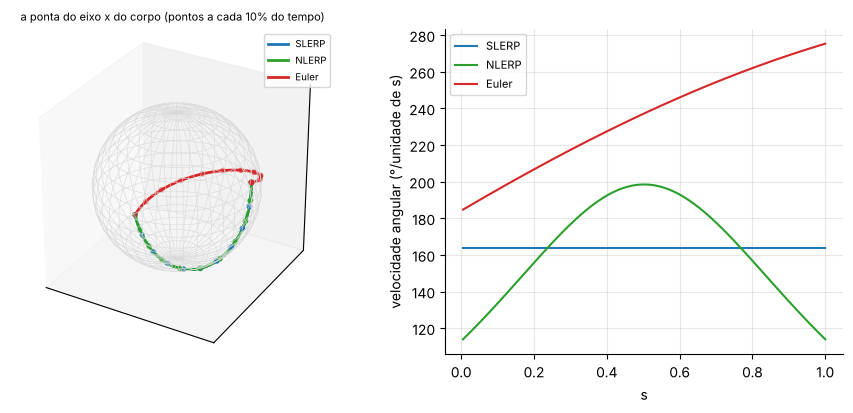

In [9]:
def euler_de_mat(R_):
    return np.array([np.arctan2(R_[2, 1], R_[2, 2]), -np.arcsin(R_[2, 0]), np.arctan2(R_[1, 0], R_[0, 0])])

q0 = qexp([0.2, -0.3, 0.1]); q1 = qexp(np.radians(150) * np.array([0.3, 0.8, -0.52]) / np.linalg.norm([0.3, 0.8, -0.52]))
ss = np.linspace(0, 1, 201)
e0, e1 = euler_de_mat(qmat(q0)), euler_de_mat(qmat(q1))
caminhos = {
    "SLERP": [slerp(q0, q1, s) for s in ss],
    "NLERP": [qnorm((1 - s) * q0 + s * (q1 if q0 @ q1 >= 0 else -q1)) for s in ss],
    "Euler": [mat_q(euler_mat((1 - s) * e0 + s * e1)) for s in ss],
}
angulo_entre = lambda a, b: np.linalg.norm(qlog(qmul(qconj(a), b)))
total = angulo_entre(q0, q1)
print(f"ângulo entre q0 e q1: {np.degrees(total):.2f}°")
medidas = {}
for nome, cam in caminhos.items():
    passos = np.array([angulo_entre(cam[k_], cam[k_ + 1]) for k_ in range(len(cam) - 1)])
    medidas[nome] = (passos.sum(), passos.max() / passos.min())
    print(f"{nome:6s}: comprimento do caminho {np.degrees(passos.sum()):7.2f}°,  maior passo / menor passo = {passos.max() / passos.min():.3f}")
confere("SLERP chega a q1", angulo_entre(caminhos["SLERP"][-1], q1), 0, tol=1e-12)
confere("SLERP anda o caminho mais curto, com velocidade constante", [medidas["SLERP"][0], medidas["SLERP"][1]], [total, 1.0], tol=1e-9)
confere("NLERP faz o mesmo caminho, com velocidade desigual", [medidas["NLERP"][0], medidas["NLERP"][1] > 1.1], [total, True], tol=1e-9)
confere("os ângulos de Euler fazem um caminho mais longo", medidas["Euler"][0] > 1.05 * total, True)

fig = plt.figure(figsize=(9, 4.2))
ax = fig.add_subplot(1, 2, 1, projection="3d")
u_, v_ = np.mgrid[0:2 * np.pi:40j, 0:np.pi:20j]
ax.plot_wireframe(np.cos(u_) * np.sin(v_), np.sin(u_) * np.sin(v_), np.cos(v_), color="0.85", lw=0.4)
for (nome, cam), cor in zip(caminhos.items(), ["C0", "C2", "C3"]):
    P = np.array([qrot(q_, [1, 0, 0]) for q_ in cam]); ax.plot(*P.T, color=cor, lw=2, label=nome)
    P10 = P[::20]; ax.scatter(*P10.T, color=cor, s=10)
ax.set_box_aspect((1, 1, 1)); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([]); ax.legend(fontsize=7)
ax.set_title("a ponta do eixo x do corpo (pontos a cada 10% do tempo)", fontsize=8)
ax2 = fig.add_subplot(1, 2, 2)
for (nome, cam), cor in zip(caminhos.items(), ["C0", "C2", "C3"]):
    passos = [angulo_entre(cam[k_], cam[k_ + 1]) * (len(cam) - 1) for k_ in range(len(cam) - 1)]
    ax2.plot(ss[1:], np.degrees(passos), color=cor, label=nome)
ax2.set_xlabel("s"); ax2.set_ylabel("velocidade angular (°/unidade de s)"); ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Leitura.** Entre duas orientações a 164° uma da outra, o SLERP anda exatamente 164°, com velocidade constante. O NLERP percorre o mesmo arco (a ponta do eixo $x$ fica sobre a curva azul), mas a velocidade varia por um fator de 1,74: lenta nas pontas, rápida no meio, porque a corda reta, normalizada, corta o arco de modo desigual. Os ângulos de Euler fazem outro caminho, 44% mais longo, com velocidade crescente. Para ângulos pequenos (de um quadro de animação ao seguinte), o NLERP é quase igual ao SLERP e mais barato; para ângulos grandes, só o SLERP dá o movimento que uma câmera real faria.

---

## 7. Sortear rotações uniformemente

Para testar um algoritmo de visão, simular moléculas ou gerar orientações iniciais num jogo, é preciso sortear rotações "ao acaso", com todas as orientações igualmente prováveis (a distribuição de Haar em $SO(3)$). Duas receitas:
- **ingênua:** sortear os três ângulos de Euler uniformemente nos seus intervalos;
- **de Shoemake (1992):** com três uniformes $u_1,u_2,u_3\in[0,1)$, $q=\big(\sqrt{1-u_1}\,\mathrm{sen}\,2\pi u_2,\ \sqrt{1-u_1}\cos2\pi u_2,\ \sqrt{u_1}\,\mathrm{sen}\,2\pi u_3,\ \sqrt{u_1}\cos2\pi u_3\big)$, um ponto uniforme em $S^3$. (Normalizar quatro gaussianas dá o mesmo.)

Duas propriedades da distribuição uniforme servem de teste: a imagem de um eixo fixo é **uniforme na esfera** (o cosseno do ângulo polar é uniforme em $[-1,1]$, o teorema de Arquimedes), e o **ângulo de rotação** $\theta$ tem distribuição acumulada $F(\theta)=(\theta-\mathrm{sen}\,\theta)/\pi$. A célula aplica o teste de Kolmogorov–Smirnov às duas.

Shoemake       :  valor-p (ângulo de rotação) = 0.861;   valor-p (eixo z na esfera) = 0.648
4 gaussianas   :  valor-p (ângulo de rotação) = 0.132;   valor-p (eixo z na esfera) = 0.989
Euler uniforme :  valor-p (ângulo de rotação) = 1.8e-16;   valor-p (eixo z na esfera) = 5.23e-91
OK   Shoemake e as gaussianas passam nos dois testes (p > 0,01):  diferença máxima = 0.00e+00
OK   os ângulos de Euler uniformes são rejeitados (p < 10⁻⁶):  diferença máxima = 0.00e+00


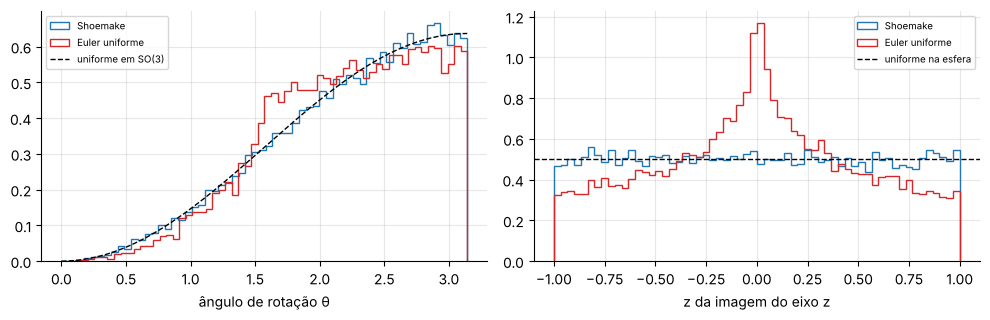

In [10]:
N = 20000
u1, u2, u3 = rng.random((3, N))
shoemake = np.column_stack([np.sqrt(1 - u1) * np.sin(2 * np.pi * u2), np.sqrt(1 - u1) * np.cos(2 * np.pi * u2),
                            np.sqrt(u1) * np.sin(2 * np.pi * u3), np.sqrt(u1) * np.cos(2 * np.pi * u3)])
gauss = qnorm(rng.normal(size=(N, 4)))
eul = np.column_stack([rng.uniform(-np.pi, np.pi, N), rng.uniform(-np.pi / 2, np.pi / 2, N), rng.uniform(-np.pi, np.pi, N)])
ingenua = np.array([mat_q(euler_mat(a_)) for a_ in eul])

F_ang = lambda th: (th - np.sin(th)) / np.pi
pvals = {}
for nome, qs in [("Shoemake", shoemake), ("4 gaussianas", gauss), ("Euler uniforme", ingenua)]:
    ang = 2 * np.arctan2(np.linalg.norm(qs[:, 1:], axis=1), np.abs(qs[:, 0]))
    zimg = 1 - 2 * (qs[:, 1]**2 + qs[:, 2]**2)                      # componente z da imagem do eixo z
    p1 = stats.kstest(ang, F_ang).pvalue; p2 = stats.kstest(zimg, stats.uniform(-1, 2).cdf).pvalue
    pvals[nome] = (p1, p2)
    print(f"{nome:15s}:  valor-p (ângulo de rotação) = {p1:.3g};   valor-p (eixo z na esfera) = {p2:.3g}")
confere("Shoemake e as gaussianas passam nos dois testes (p > 0,01)", min(*pvals["Shoemake"], *pvals["4 gaussianas"]) > 0.01, True)
confere("os ângulos de Euler uniformes são rejeitados (p < 10⁻⁶)", min(pvals["Euler uniforme"]) < 1e-6, True)

fig, axs = plt.subplots(1, 2, figsize=(10, 3.3))
for nome, qs, cor in [("Shoemake", shoemake, "C0"), ("Euler uniforme", ingenua, "C3")]:
    ang = 2 * np.arctan2(np.linalg.norm(qs[:, 1:], axis=1), np.abs(qs[:, 0]))
    axs[0].hist(ang, bins=60, density=True, histtype="step", color=cor, label=nome)
    zimg = 1 - 2 * (qs[:, 1]**2 + qs[:, 2]**2)
    axs[1].hist(zimg, bins=60, density=True, histtype="step", color=cor, label=nome)
th_ = np.linspace(0, np.pi, 200); axs[0].plot(th_, (1 - np.cos(th_)) / np.pi, "k--", lw=1, label="uniforme em SO(3)")
axs[1].axhline(0.5, color="k", ls="--", lw=1, label="uniforme na esfera")
axs[0].set_xlabel("ângulo de rotação θ"); axs[1].set_xlabel("z da imagem do eixo z")
for ax in axs: ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

**Leitura.** As duas receitas baseadas em $S^3$ passam nos dois testes, com valores-p entre 0,13 e 0,99. Os ângulos de Euler uniformes são rejeitados com valores-p de $10^{-16}$ e $10^{-91}$, e o histograma mostra por quê: a imagem do eixo $z$ se concentra perto do equador ($z\approx0$) e falta perto dos polos. Na convenção ZYX, a componente $z$ da imagem do eixo $z$ é $\cos\theta\cos\phi$, o produto dos cossenos de dois ângulos sorteados uniformemente, e um produto de cossenos se acumula perto de zero. Um teste de visão computacional com rotações "aleatórias" desse tipo testaria o algoritmo muito mais em umas orientações do que em outras.

---

## 8. Rotações exatas com quaternions inteiros

No domínio V, um inteiro gaussiano $a$ dava uma rotação racional exata do plano. No espaço, um quaternion de **inteiros** $q=(w,x,y,z)$ dá a rotação $R(q/|q|)$, cujas entradas são inteiros divididos por $|q|^2=w^2+x^2+y^2+z^2$: uma matriz **racional** exatamente ortogonal (a parametrização de Euler–Rodrigues). E o produto de quaternions inteiros é inteiro, com $|pq|^2=|p|^2|q|^2$ exato. A célula compõe 200 rotações sorteadas com componentes entre $-3$ e $3$ em inteiros do Python e, ao lado, em `float`.

In [11]:
def mat_racional(q):
    w, x, y, z = [int(c_) for c_ in q]; n2 = w * w + x * x + y * y + z * z
    F = lambda a_: Fraction(a_, n2)
    return [[F(w*w + x*x - y*y - z*z), F(2 * (x*y - w*z)), F(2 * (x*z + w*y))],
            [F(2 * (x*y + w*z)), F(w*w - x*x + y*y - z*z), F(2 * (y*z - w*x))],
            [F(2 * (x*z - w*y)), F(2 * (y*z + w*x)), F(w*w - x*x - y*y + z*z)]]

fatores = []
while len(fatores) < 200:
    f_ = rng.integers(-3, 4, size=4)
    if np.any(f_ != 0): fatores.append(Q(*[int(c_) for c_ in f_]))
exato = Q(1); flutuante = np.array([1.0, 0, 0, 0]); R_float = np.eye(3)
for f_ in fatores:
    exato = exato * f_
    flutuante = qmul(flutuante, qnorm(f_.vet().astype(float)))
    R_float = R_float @ qmat(qnorm(f_.vet().astype(float)))
n2 = exato.norma2()
prod_n2 = 1
for f_ in fatores: prod_n2 *= f_.norma2()
confere("|produto|² = produto dos |fator|² (quatro quadrados, exato)", n2 == prod_n2, True)
Rx = mat_racional(exato.vet())
RtR = [[sum(Rx[a_][m] * Rx[b_][m] for m in range(3)) for b_ in range(3)] for a_ in range(3)]
confere("a matriz racional é exatamente ortogonal", all(RtR[a_][b_] == (1 if a_ == b_ else 0) for a_ in range(3) for b_ in range(3)), True)
print(f"o quaternion exato tem componentes de até {max(len(str(abs(c_))) for c_ in exato.vet())} dígitos; |q|² tem {len(str(n2))} dígitos")
erro_q = abs(np.linalg.norm(flutuante) - 1); erro_R = np.abs(R_float.T @ R_float - np.eye(3)).max()
print(f"em float, depois de 200 produtos: | |q| − 1 | = {erro_q:.1e};  as 200 matrizes multiplicadas: |RᵀR − I| = {erro_R:.1e}")
confere("o float erra pouco, mas erra", [erro_q > 0 or erro_R > 0], [True])
confere("e o float concorda com o exato até o arredondamento", qmat(flutuante), np.array([[float(x_) for x_ in l_] for l_ in Rx]), tol=1e-12)

OK   |produto|² = produto dos |fator|² (quatro quadrados, exato):  diferença máxima = 0.00e+00
OK   a matriz racional é exatamente ortogonal:  diferença máxima = 0.00e+00
o quaternion exato tem componentes de até 116 dígitos; |q|² tem 231 dígitos
em float, depois de 200 produtos: | |q| − 1 | = 5.6e-15;  as 200 matrizes multiplicadas: |RᵀR − I| = 2.2e-14
OK   o float erra pouco, mas erra:  diferença máxima = 0.00e+00
OK   e o float concorda com o exato até o arredondamento:  diferença máxima = 2.04e-14


**Leitura.** O produto inteiro guarda tudo: $|q|^2$ é o produto exato das 200 normas, e a matriz racional é ortogonal sem erro nenhum. O preço é o de sempre: os números crescem (cada fator multiplica $|q|^2$ por até 36), e depois de 200 produtos o quaternion tem dezenas de dígitos. Em `float`, quaternion e matrizes se afastam da unitariedade e da ortogonalidade só na casa de $10^{-15}$ a $10^{-14}$, e concordam com o exato. Repare que compor 200 matrizes custa 27 multiplicações por passo, contra 16 do produto de quaternions.

> **Nota: Lipschitz e Hurwitz.** Os quaternions de componentes inteiras são os **inteiros de Lipschitz**. Hurwitz (1919) mostrou que o conjunto certo para fazer aritmética (com divisão euclidiana, como nos inteiros gaussianos) inclui também os quaternions de componentes todas **meio-inteiras**, como $\tfrac12(1+\mathbf i+\mathbf j+\mathbf k)$. Os 24 inteiros de Hurwitz de norma 1 são as rotações de simetria de um tetraedro regular, cada uma contada duas vezes (o exercício 1 vai mais longe, com o cubo).

---

## 9. A interface de domínio para $SO(3)$

| operação | significado | com quaternions |
|---|---|---|
| `compoe(g, h)` | fazer $g$, depois $h$ (no referencial de $g$) | $q_gq_h$ |
| `inverso(g)` | desfazer | $q_g^*$ |
| `identidade` | não girar | $1$ |
| `Exp(φ)` | girar com velocidade angular $\boldsymbol\varphi$ (no corpo) por uma unidade de tempo | seção 5 |
| `Log(g)` | o vetor de rotação de $g$, com $\lvert\boldsymbol\varphi\rvert\le\pi$ | seção 5 |
| $x\boxplus\delta$ | perturbar $x$ por $\delta$ **no referencial do corpo** | $q_x\,\mathrm{Exp}(\delta)$ |

Os testes são os mesmos dos domínios anteriores, mais dois: a não comutatividade, e o fato de que $q$ e $-q$ são o **mesmo** elemento para $\boxminus$ (o $\mathrm{Log}$ escolhe o representante com $w\ge0$).

In [12]:
class DominioSO3:
    """Domínio VI: rotações do espaço como quaternions unitários."""
    nome = "SO(3) (quaternions)"
    dim = 3
    identidade = np.array([1.0, 0, 0, 0])
    def compoe(self, g, h): return qmul(g, h)
    def inverso(self, g):   return qconj(g)
    def Exp(self, phi):     return qexp(phi)
    def Log(self, g):       return qlog(g)
    def mais(self, x, d):   return self.compoe(x, self.Exp(d))
    def menos(self, y, x):  return self.Log(self.compoe(self.inverso(x), y))

def testa_dominio(D, amostra, tol=1e-12):
    g, h, k_ = amostra(), amostra(), amostra()
    print(f"domínio {D.nome}")
    confere("  associatividade da composição", D.menos(D.compoe(D.compoe(g, h), k_), D.compoe(g, D.compoe(h, k_))), 0, tol)
    confere("  identidade", D.menos(D.compoe(g, D.identidade), g), 0, tol)
    confere("  inverso", D.menos(D.compoe(g, D.inverso(g)), D.identidade), 0, tol)
    d = D.Log(amostra()) * 0.3
    confere("  Log(Exp(δ)) = δ", D.Log(D.Exp(d)), d, tol)
    confere("  (x ⊞ δ) ⊟ x = δ", D.menos(D.mais(g, d), g), d, tol)
    confere("  x ⊞ (y ⊟ x) = y", D.menos(D.mais(g, D.menos(h, g)), h), 0, tol)

S = DominioSO3()
amostra = lambda: qnorm(rng.normal(size=4))
testa_dominio(S, amostra)
g, h = amostra(), amostra()
dif = S.menos(S.compoe(g, h), S.compoe(h, g))
print("\ng·h ⊟ h·g =", dif)
confere("o grupo não é comutativo", np.linalg.norm(dif) > 0.1, True)
confere("q e −q são o mesmo elemento", S.menos(-g, g), 0, tol=1e-15)
d = np.array([0.3, 0.5, -0.2])
print("x·Exp(δ) ⊟ Exp(δ)·x =", S.menos(S.compoe(g, S.Exp(d)), S.compoe(S.Exp(d), g)), " ← perturbar no corpo ≠ perturbar no mundo")

domínio SO(3) (quaternions)
OK     associatividade da composição:  diferença máxima = 3.33e-16
OK     identidade:  diferença máxima = 2.78e-17
OK     inverso:  diferença máxima = 2.78e-17
OK     Log(Exp(δ)) = δ:  diferença máxima = 0.00e+00
OK     (x ⊞ δ) ⊟ x = δ:  diferença máxima = 1.11e-16
OK     x ⊞ (y ⊟ x) = y:  diferença máxima = 4.09e-16

g·h ⊟ h·g = [ 0.389108 -2.376075 -2.004096]
OK   o grupo não é comutativo:  diferença máxima = 0.00e+00
OK   q e −q são o mesmo elemento:  diferença máxima = 2.93e-18
x·Exp(δ) ⊟ Exp(δ)·x = [ 0.767133  0.890143 -0.083552]  ← perturbar no corpo ≠ perturbar no mundo


**Para pensar.** Nos domínios IV e V, perturbar a orientação no corpo ou no mundo dava o mesmo resultado, porque rotações do plano comutam; a diferença do domínio V estava só na translação. Aqui, $q\,\mathrm{Exp}(\delta)$ e $\mathrm{Exp}(\delta)\,q$ diferem já na orientação, e a ponte entre os dois é a matriz de rotação: $\mathrm{Exp}(\delta)\,q=q\,\mathrm{Exp}(R(q)^\top\delta)$. A matriz $\mathrm{Ad}_q$ do domínio V, em $SO(3)$, é a própria $R(q)$.

---

## 10. Exercícios

1. **As 24 rotações do cubo.** O grupo das rotações de simetria do cubo tem 24 elementos. Monte os 48 quaternions correspondentes (eles incluem os 24 inteiros de Hurwitz unitários e mais 24 da forma $\tfrac1{\sqrt2}(\pm1\pm\mathbf i)$ e permutações). Confira que o conjunto é fechado pelo produto e que cada rotação aparece duas vezes.
2. **O cinto de verdade.** Pegue um cinto ou uma fita, prenda uma ponta e gire a outra 720°. Desfaça a torção sem girar a ponta, só passando o cinto em volta dela. Depois tente com 360°. Relacione com a seção 3.
3. **Outra convenção de Euler.** Refaça a seção 4 com a ordem XYZ. Onde fica a singularidade agora? Há alguma ordem de três eixos sem singularidade?
4. **SLERP pelo caminho longo.** Na seção 6, troque $q_1$ por $-q_1$ e interpole sem a escolha do representante (calcule $\mathrm{Exp}(s\,\mathrm{Log}(q_0^*q_1))$ com um $\mathrm{Log}$ que não force $w\ge0$). Qual é o comprimento do caminho?
5. **Rotações uniformes por rejeição.** Sorteie pontos uniformes no cubo $[-1,1]^4$, rejeite os de norma maior que 1 e normalize os restantes. A distribuição é uniforme? Quantos pontos são rejeitados, em média?